<a href="https://colab.research.google.com/github/sociallyH03ly/Palay-Production-Costs-and-Returns-2022-2025-Analysis-from-PSA/blob/main/Palay_2022_2025_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌾 Palay Production Costs and Returns, 2022–2025: Complete Analysis

**Source:** PSA OpenSTAT, *Palay: Average Production Costs and Returns by Type, Geolocation, Item, Cropping Season and Year*. Values are PhP per hectare (cost per kg in PhP/kg).


Run the cells top to bottom. The first code cell asks you to upload the CSV once; both parts use it.

# Part 1: Exploratory Data Analysis

## 1.1 Setup and load data

In [ ]:
import re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 30

In [ ]:
# Upload the CSV when running in Google Colab (falls back to a CSV in the working folder elsewhere)
try:
    from google.colab import files
    uploaded = files.upload()
    CSV_PATH = next(iter(uploaded))
except ImportError:
    CSV_PATH = [f for f in glob.glob("*.csv") if not f.startswith("palay_clean")][0]
print("Using:", CSV_PATH)

Using: Palay-_Average_Production_Costs_and_Returns_by_Type__Geolocation__Item__Cropping_Season_and_Year-_2022-2025.csv


In [ ]:
raw = pd.read_csv(CSV_PATH)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (2346, 16)


,Type,Geolocation,Unnamed: 2,Item,January to June 2022,January to June 2023,January to June 2024,January to June 2025,July to December 2022,July to December 2023,July to December 2024,July to December 2025,Average 2022,Average 2023,Average 2024,Average 2025
0,Palay,PHILIPPINES,NaN,CASH COSTS,30098.12,30302.54,30102.53,28848.17,31048.1,29150.35,29208.39,28938.54,30573.11,29726.44,29655.46,28893.36
1,Palay,PHILIPPINES,NaN,..Seeds,1673.18,1724.56,2308.78,1739.39,1714.24,2026.7,2113.71,1594.54,1693.71,1875.63,2211.25,1666.97
2,Palay,PHILIPPINES,NaN,..Fertilizer,9938.2,9240.45,7137.05,6100.14,11359.34,7809.68,7161.2,6407.17,10648.77,8525.06,7149.12,6253.65
3,Palay,PHILIPPINES,NaN,..Pesticides,2518,2513.05,2376.35,2314.37,2437.02,2857.62,2716.86,2646,2477.51,2685.33,2546.6,2480.19
4,Palay,PHILIPPINES,NaN,..Hired labor,10238.71,10747.46,11853.74,12282.76,10160.13,10915.8,11554.9,12505.68,10199.42,10831.63,11704.32,12394.22


## 1.2 Cleaning

What the raw file needs:
- an empty third column (`Unnamed: 2`) → drop
- `..` marks a value that is not available → convert to `NaN`
- sub-items are prefixed with `..` (e.g. `..Seeds`) → strip the prefix, but remember they are sub-items
- every number is stored as text → convert to numeric
- add a **Category** (Cash / Non-cash / Imputed / Summary) so costs can be grouped

In [ ]:
df = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")]).copy()

value_cols = list(df.columns[3:])
for c in value_cols:
    df[c] = pd.to_numeric(df[c].replace("..", np.nan), errors="coerce")

df["Is_subitem"] = df["Item"].str.startswith("..")
df["Item"] = df["Item"].str.lstrip(".").str.strip()

# Category: sub-items belong to the most recent cost header above them
headers = {"CASH COSTS": "Cash cost", "NON-CASH COSTS": "Non-cash cost", "IMPUTED COSTS": "Imputed cost"}
cat, current = [], "Summary"
for item, sub in zip(df["Item"], df["Is_subitem"]):
    if item in headers:
        current = headers[item]
    elif not sub:
        current = "Summary"
    cat.append(current if (sub or item in headers) else "Summary")
df["Category"] = cat

# Friendlier region names
short = {
    "PHILIPPINES": "Philippines",
    "Cordillera Administrative Region (CAR)": "CAR",
    "Region I (Ilocos Region)": "I - Ilocos",
    "Region II (Cagayan Valley)": "II - Cagayan Valley",
    "Region III (Central Luzon)": "III - Central Luzon",
    "Region IV-A (CALABARZON)": "IV-A - CALABARZON",
    "MIMAROPA Region": "MIMAROPA",
    "Region V (Bicol Region)": "V - Bicol",
    "Region VI (Western Visayas)": "VI - Western Visayas",
    "Region VII (Central Visayas)": "VII - Central Visayas",
    "Region VIII (Eastern Visayas)": "VIII - Eastern Visayas",
    "Region IX (Zamboanga Peninsula)": "IX - Zamboanga",
    "Region X (Northern Mindanao)": "X - Northern Mindanao",
    "Region XI (Davao Region)": "XI - Davao",
    "Region XII (SOCCSKSARGEN)": "XII - SOCCSKSARGEN",
    "Region XIII (Caraga)": "XIII - Caraga",
    "Bangsamoro Autonomous Region in Muslim Mindanao (BARMM)": "BARMM",
}
df["Region"] = df["Geolocation"].map(short)
assert df["Region"].notna().all(), "unmapped region name"
df.head()

,Type,Geolocation,Item,January to June 2022,January to June 2023,January to June 2024,January to June 2025,July to December 2022,July to December 2023,July to December 2024,July to December 2025,Average 2022,Average 2023,Average 2024,Average 2025,Is_subitem,Category,Region
0,Palay,PHILIPPINES,CASH COSTS,"30,098.12","30,302.54","30,102.53","28,848.17","31,048.10","29,150.35","29,208.39","28,938.54","30,573.11","29,726.44","29,655.46","28,893.36",False,Cash cost,Philippines
1,Palay,PHILIPPINES,Seeds,"1,673.18","1,724.56","2,308.78","1,739.39","1,714.24","2,026.70","2,113.71","1,594.54","1,693.71","1,875.63","2,211.25","1,666.97",True,Cash cost,Philippines
2,Palay,PHILIPPINES,Fertilizer,"9,938.20","9,240.45","7,137.05","6,100.14","11,359.34","7,809.68","7,161.20","6,407.17","10,648.77","8,525.06","7,149.12","6,253.65",True,Cash cost,Philippines
3,Palay,PHILIPPINES,Pesticides,"2,518.00","2,513.05","2,376.35","2,314.37","2,437.02","2,857.62","2,716.86","2,646.00","2,477.51","2,685.33","2,546.60","2,480.19",True,Cash cost,Philippines
4,Palay,PHILIPPINES,Hired labor,"10,238.71","10,747.46","11,853.74","12,282.76","10,160.13","10,915.80","11,554.90","12,505.68","10,199.42","10,831.63","11,704.32","12,394.22",True,Cash cost,Philippines


## 1.3 Structure, missing values and integrity checks

In [ ]:
print(f"Rows: {len(df):,}  |  Value columns: {len(value_cols)}")
print("Types   :", df["Type"].unique().tolist())
print("Regions :", df["Region"].nunique(), "(incl. national total)")
print("Items   :", df["Item"].nunique())
print("Periods : Jan–Jun, Jul–Dec and Annual average for 2022–2025")
print("Rows per Type × Region (should all be equal):", df.groupby(["Type", "Region"]).size().unique())

Rows: 2,346  |  Value columns: 12
Types   : ['Palay', 'Irrigated Palay', 'Non-Irrigated Palay']
Regions : 17 (incl. national total)
Items   : 46
Periods : Jan–Jun, Jul–Dec and Annual average for 2022–2025
Rows per Type × Region (should all be equal): [46]


In [ ]:
# Missing values: which items are '..' and how often?
miss = (df[value_cols].isna().sum(axis=1) > 0)
missing_by_item = (df.assign(any_missing=miss)
                     .groupby(["Category", "Item"])["any_missing"].agg(["sum", "size"])
                     .rename(columns={"sum": "rows_with_missing", "size": "rows"}))
missing_by_item["pct_missing"] = missing_by_item["rows_with_missing"] / missing_by_item["rows"] * 100
missing_by_item = missing_by_item[missing_by_item["rows_with_missing"] > 0].sort_values("pct_missing", ascending=False)
print(f"Total missing cells: {int(df[value_cols].isna().sum().sum()):,} of {df[value_cols].size:,} "
      f"({df[value_cols].isna().sum().sum() / df[value_cols].size:.1%})")
missing_by_item.head(15)

Total missing cells: 1,452 of 28,152 (5.2%)


rows_with_missing  rows  \
Category      Item                                                        
Non-cash cost Other permanent employees'salary                 42    51   
              Fertilizer in kind                               26    51   
Cash cost     Irrigation fee                                   19    51   
Non-cash cost Pesticides in kind                               19    51   
              Seeds in kind                                    18    51   
Cash cost     Sacks and tying materials                        14    51   
Non-cash cost Harvesters' share                                 9    51   
              Others b/                                         8    51   
Imputed cost  Pesticides imputed                                8    51   
Non-cash cost Threshers' share                                  6    51   
              Caretaker/overseer's wages                        6    51   
Cash cost     Interest payment on crop loan                     5    51   
Non-cash cost Rentals in kind                                   3    51   
              Hired labor in kind                               2    51   
Cash cost     Repairs                                           2    51   

                                                pct_missing  
Category      Item                                           
Non-cash cost Other permanent employees'salary        82.35  
              Fertilizer in kind                      50.98  
Cash cost     Irrigation fee                          37.25  
Non-cash cost Pesticides in kind                      37.25  
              Seeds in kind                           35.29  
Cash cost     Sacks and tying materials               27.45  
Non-cash cost Harvesters' share                       17.65  
              Others b/                               15.69  
Imputed cost  Pesticides imputed                      15.69  
Non-cash cost Threshers' share                        11.76  
              Caretaker/overseer's wages              11.76  
Cash cost     Interest payment on crop loan            9.80  
Non-cash cost Rentals in kind                          5.88  
              Hired labor in kind                      3.92  
Cash cost     Repairs                                  3.92

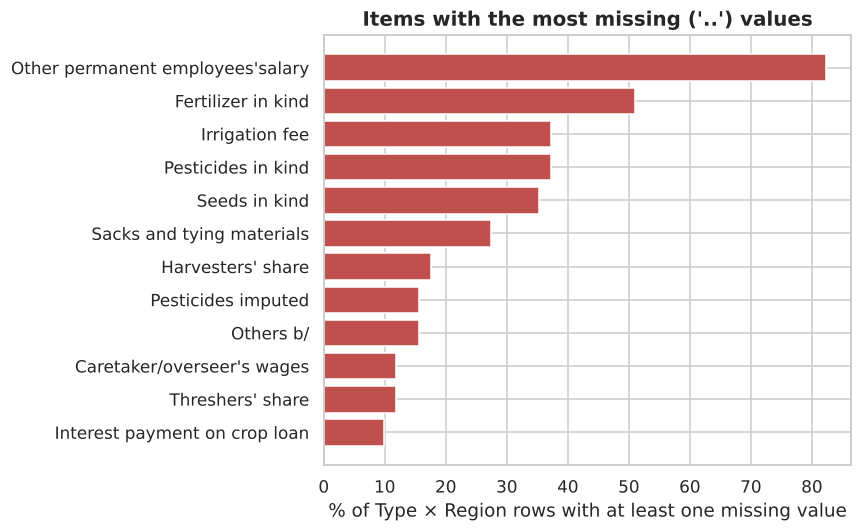

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
top = missing_by_item.head(12).reset_index().sort_values("pct_missing")
ax.barh(top["Item"], top["pct_missing"], color="#c0504d")
ax.set_xlabel("% of Type × Region rows with at least one missing value")
ax.set_title("Items with the most missing ('..') values")
plt.tight_layout(); plt.show()

In [ ]:
# Integrity checks on the Annual-average columns:
#   Total = Cash + Non-cash + Imputed ;  Net = Gross − Total ;  NPCR ≈ Net / Total
avg_cols = [c for c in value_cols if c.startswith("Average")]
piv = {c: df.pivot_table(index=["Type", "Region"], columns="Item", values=c) for c in avg_cols}
rows = []
for c, p in piv.items():
    rows.append({
        "column": c,
        "max |Total − (Cash+NonCash+Imputed)|": (p["TOTAL COSTS"] - p[["CASH COSTS", "NON-CASH COSTS", "IMPUTED COSTS"]].sum(axis=1)).abs().max(),
        "max |Net − (Gross − Total)|": (p["NET RETURNS"] - (p["GROSS RETURNS"] - p["TOTAL COSTS"])).abs().max(),
        "max |NPCR − Net/Total|": (p["NET PROFIT - COST RATIO"] - p["NET RETURNS"] / p["TOTAL COSTS"]).abs().max(),
    })
pd.DataFrame(rows).set_index("column")

,max |Total − (Cash+NonCash+Imputed)|,max |Net − (Gross − Total)|,max |NPCR − Net/Total|
column,,,
Average 2022,0.01,0.01,0.00
Average 2023,0.01,0.01,0.00
Average 2024,0.01,0.01,0.00
Average 2025,0.01,0.01,0.00


## 1.4 Reshape to long format and compute descriptive statistics
A tidy (long) table makes grouping and plotting much easier: one row per Type × Region × Item × Year × Period.

In [ ]:
long = df.melt(id_vars=["Type", "Region", "Item", "Category", "Is_subitem"],
               value_vars=value_cols, var_name="Column", value_name="Value")

def parse(col):
    year = int(re.search(r"(\d{4})", col).group(1))
    if col.startswith("January"): return "Jan–Jun", year
    if col.startswith("July"):    return "Jul–Dec", year
    return "Annual average", year

long[["Period", "Year"]] = long["Column"].apply(lambda c: pd.Series(parse(c)))
long = long.drop(columns="Column")

REGIONS = [r for r in short.values() if r != "Philippines"]
KEY = ["TOTAL COSTS", "GROSS RETURNS", "NET RETURNS", "NET PROFIT - COST RATIO", "Cost per kilogram (in PhP)"]

def get(item, typ="Palay", period="Annual average", region=None, regions=False):
    d = long[(long.Item == item) & (long.Type == typ) & (long.Period == period)]
    if regions:   return d[d.Region != "Philippines"]
    if region:    return d[d.Region == region]
    return d[d.Region == "Philippines"]

long.head()

,Type,Region,Item,Category,Is_subitem,Value,Period,Year
0,Palay,Philippines,CASH COSTS,Cash cost,False,"30,098.12",Jan–Jun,2022
1,Palay,Philippines,Seeds,Cash cost,True,"1,673.18",Jan–Jun,2022
2,Palay,Philippines,Fertilizer,Cash cost,True,"9,938.20",Jan–Jun,2022
3,Palay,Philippines,Pesticides,Cash cost,True,"2,518.00",Jan–Jun,2022
4,Palay,Philippines,Hired labor,Cash cost,True,"10,238.71",Jan–Jun,2022


In [ ]:
# Descriptive statistics of the 16 regions (Annual average, all palay), per key metric
stats = (long[(long.Type == "Palay") & (long.Period == "Annual average") & (long.Item.isin(KEY)) & (long.Region != "Philippines")]
         .groupby(["Item", "Year"])["Value"].agg(["count", "mean", "median", "std", "min", "max"]))
stats

count      mean    median       std  \
Item                       Year                                        
Cost per kilogram (in PhP) 2022     16     15.73     14.95      2.65   
                           2023     16     13.87     13.66      1.63   
                           2024     16     14.96     14.58      1.92   
                           2025     16     13.95     13.60      1.50   
GROSS RETURNS              2022     16 62,876.03 61,049.82 14,367.52   
                           2023     16 79,732.97 73,986.02 16,276.02   
                           2024     16 89,697.76 83,108.80 20,648.43   
                           2025     16 69,549.11 66,080.81 14,121.74   
NET PROFIT - COST RATIO    2022     16      0.18      0.21      0.16   
                           2023     16      0.45      0.43      0.18   
                           2024     16      0.55      0.57      0.26   
                           2025     16      0.26      0.27      0.20   
NET RETURNS                2022     16  9,645.21 10,796.32  9,293.66   
                           2023     16 24,780.63 22,172.06 11,137.33   
                           2024     16 31,771.99 29,824.02 16,068.05   
                           2025     16 14,222.99 13,897.20 11,648.30   
TOTAL COSTS                2022     16 53,230.81 54,199.38  8,403.32   
                           2023     16 54,952.34 55,285.01  8,438.08   
                           2024     16 57,925.77 58,618.79  8,786.59   
                           2025     16 55,326.12 55,907.63  6,601.55   

                                       min        max  
Item                       Year                        
Cost per kilogram (in PhP) 2022      12.85      22.43  
                           2023      11.71      18.20  
                           2024      12.59      17.96  
                           2025      11.82      16.79  
GROSS RETURNS              2022  43,102.42  86,158.27  
                           2023  60,575.02 111,363.99  
                           2024  52,419.17 125,485.69  
                           2025  44,961.57  88,439.45  
NET PROFIT - COST RATIO    2022      -0.19       0.44  
                           2023       0.11       0.81  
                           2024      -0.06       0.92  
                           2025      -0.19       0.58  
NET RETURNS                2022  -9,904.20  25,002.21  
                           2023   5,920.13  49,969.68  
                           2024  -3,174.87  59,105.71  
                           2025 -10,231.78  32,436.25  
TOTAL COSTS                2022  40,033.00  69,537.38  
                           2023  42,666.52  74,294.42  
                           2024  45,557.60  76,440.07  
                           2025  43,536.32  66,261.33

In [ ]:
# National cost items: how big is each and how did it change 2022 → 2025?
nat = (long[(long.Type == "Palay") & (long.Period == "Annual average") & (long.Region == "Philippines") & (long.Is_subitem)]
       .pivot_table(index=["Category", "Item"], columns="Year", values="Value"))
nat["Change 2022→2025"] = nat[2025] - nat[2022]
nat["% change"] = nat["Change 2022→2025"] / nat[2022] * 100
nat.sort_values(2025, ascending=False).head(12)

Year                                             2022      2023      2024  \
Category      Item                                                          
Cash cost     Hired labor                   10,199.42 10,831.63 11,704.32   
              Fertilizer                    10,648.77  8,525.06  7,149.12   
Imputed cost  Rental value of owned land     3,932.76  4,383.58  5,106.95   
              Operator labor                 3,119.34  3,309.66  3,582.11   
Non-cash cost Reaper's share                 2,646.27  3,366.20  3,911.26   
              Landowner's share              2,990.26  3,312.30  3,903.14   
Cash cost     Pesticides                     2,477.51  2,685.33  2,546.60   
Imputed cost  Family labor                   1,739.28  1,848.05  1,995.12   
              Interest on operating capital  1,433.61  1,806.02  1,863.88   
Cash cost     Seeds                          1,693.71  1,875.63  2,211.25   
Imputed cost  Seeds imputed                  1,606.72  1,775.53  2,101.32   
Cash cost     Fuel & Oil                     1,449.36  1,443.27  1,454.29   

Year                                             2025  Change 2022→2025  \
Category      Item                                                        
Cash cost     Hired labor                   12,394.22          2,194.80   
              Fertilizer                     6,253.65         -4,395.12   
Imputed cost  Rental value of owned land     3,850.16            -82.60   
              Operator labor                 3,786.76            667.42   
Non-cash cost Reaper's share                 2,983.89            337.62   
              Landowner's share              2,942.42            -47.84   
Cash cost     Pesticides                     2,480.19              2.68   
Imputed cost  Family labor                   2,114.76            375.48   
              Interest on operating capital  1,783.03            349.42   
Cash cost     Seeds                          1,666.97            -26.74   
Imputed cost  Seeds imputed                  1,584.07            -22.65   
Cash cost     Fuel & Oil                     1,446.18             -3.18   

Year                                         % change  
Category      Item                                     
Cash cost     Hired labor                       21.52  
              Fertilizer                       -41.27  
Imputed cost  Rental value of owned land        -2.10  
              Operator labor                    21.40  
Non-cash cost Reaper's share                    12.76  
              Landowner's share                 -1.60  
Cash cost     Pesticides                         0.11  
Imputed cost  Family labor                      21.59  
              Interest on operating capital     24.37  
Cash cost     Seeds                             -1.58  
Imputed cost  Seeds imputed                     -1.41  
Cash cost     Fuel & Oil                        -0.22

## 1.5 Visualizations

### 1.5.1 National trend: costs, gross returns and net returns

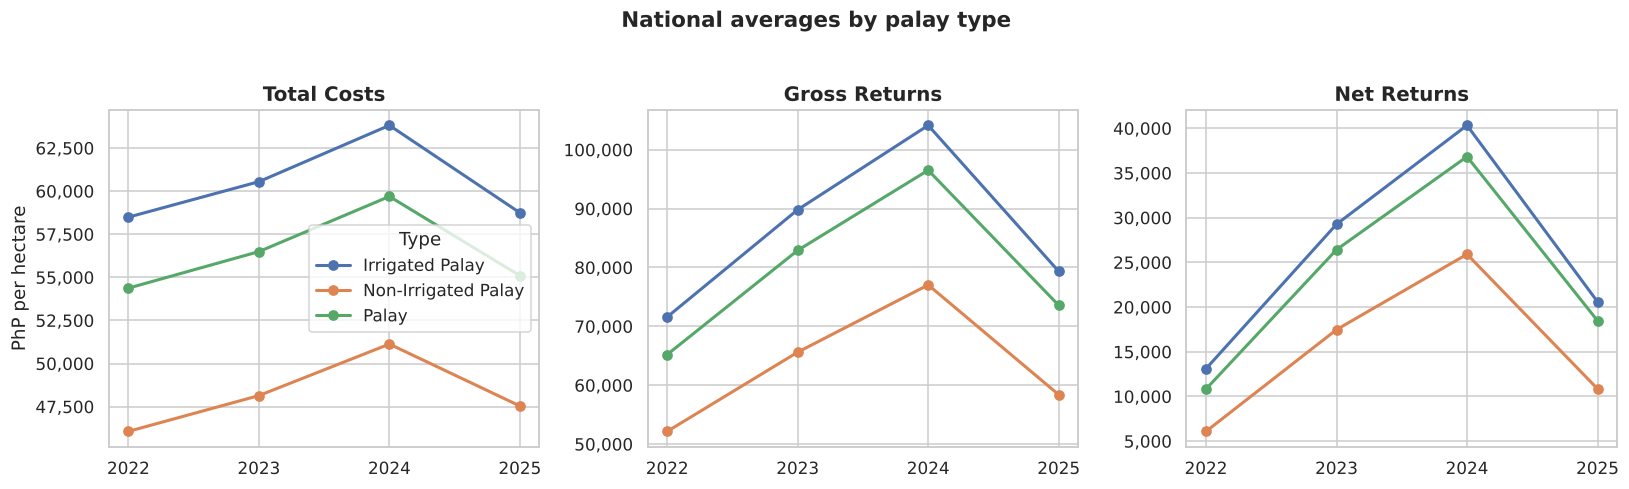

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharey=False)
for ax, item in zip(axes, ["TOTAL COSTS", "GROSS RETURNS", "NET RETURNS"]):
    for typ, g in long[(long.Item == item) & (long.Region == "Philippines") & (long.Period == "Annual average")].groupby("Type"):
        ax.plot(g["Year"], g["Value"], marker="o", lw=2, label=typ)
    ax.set_title(item.title()); ax.set_xticks([2022, 2023, 2024, 2025])
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[0].set_ylabel("PhP per hectare"); axes[0].legend(title="Type")
plt.suptitle("National averages by palay type", y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

### 1.5.2 Where does the money go? Cost structure

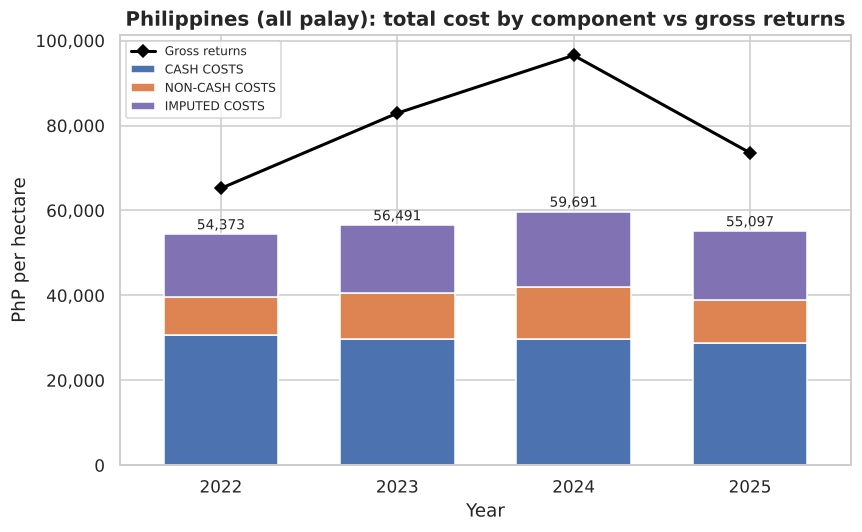

In [ ]:
cs = (long[(long.Type == "Palay") & (long.Period == "Annual average") & (long.Region == "Philippines")
           & (long.Item.isin(["CASH COSTS", "NON-CASH COSTS", "IMPUTED COSTS"]))]
      .pivot(index="Year", columns="Item", values="Value")[["CASH COSTS", "NON-CASH COSTS", "IMPUTED COSTS"]])
gross = get("GROSS RETURNS").set_index("Year")["Value"]

fig, ax = plt.subplots(figsize=(8, 5))
cs.plot(kind="bar", stacked=True, ax=ax, color=["#4c72b0", "#dd8452", "#8172b3"], width=0.65)
ax.plot(range(len(gross)), gross.values, color="black", marker="D", lw=2, label="Gross returns")
for i, (y, tot) in enumerate(cs.sum(axis=1).items()):
    ax.text(i, tot + 1200, f"{tot:,.0f}", ha="center", fontsize=9)
ax.set_xticklabels(cs.index, rotation=0); ax.set_ylabel("PhP per hectare")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Philippines (all palay): total cost by component vs gross returns"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

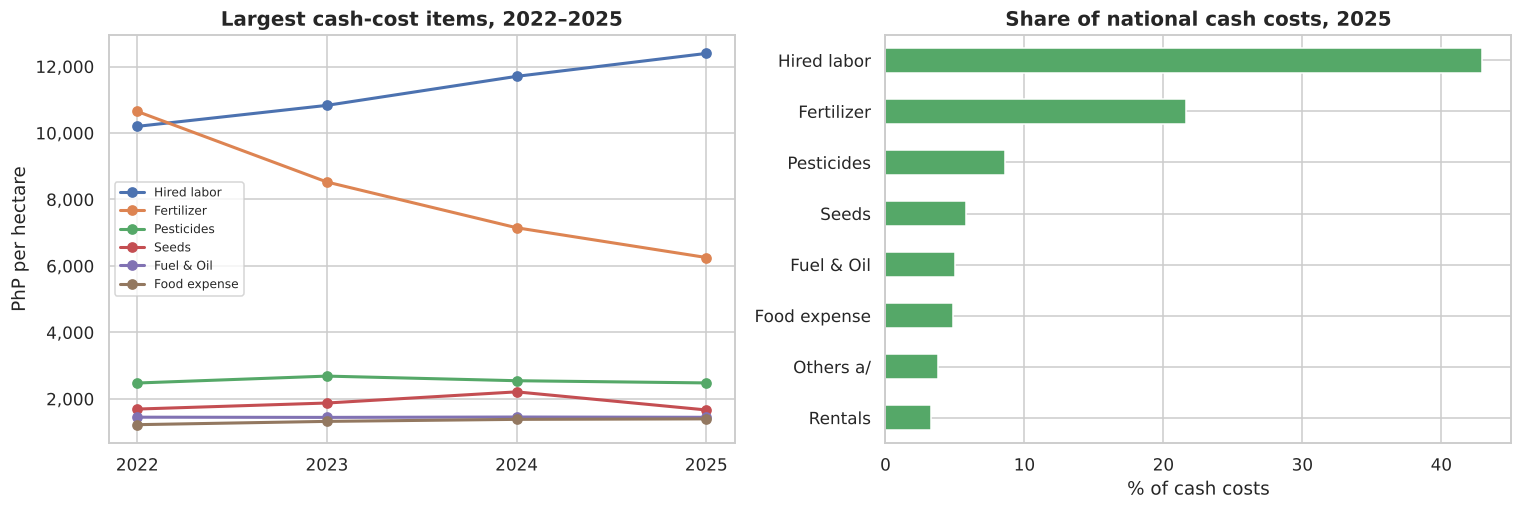

In [ ]:
# Which input costs moved the most? (Cash costs, national)
cash = (long[(long.Type == "Palay") & (long.Period == "Annual average") & (long.Region == "Philippines")
             & (long.Category == "Cash cost") & (long.Is_subitem)]
        .pivot(index="Item", columns="Year", values="Value"))
top_items = cash[2025].sort_values(ascending=False).head(6).index

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for it in top_items:
    axes[0].plot(cash.columns, cash.loc[it], marker="o", lw=2, label=it)
axes[0].set_title("Largest cash-cost items, 2022–2025"); axes[0].set_xticks(cash.columns)
axes[0].set_ylabel("PhP per hectare"); axes[0].legend(fontsize=8)
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

share = (cash[2025] / cash[2025].sum() * 100).sort_values()
share.tail(8).plot(kind="barh", ax=axes[1], color="#55a868")
axes[1].set_title("Share of national cash costs, 2025"); axes[1].set_xlabel("% of cash costs"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

### 1.5.3 Regional performance

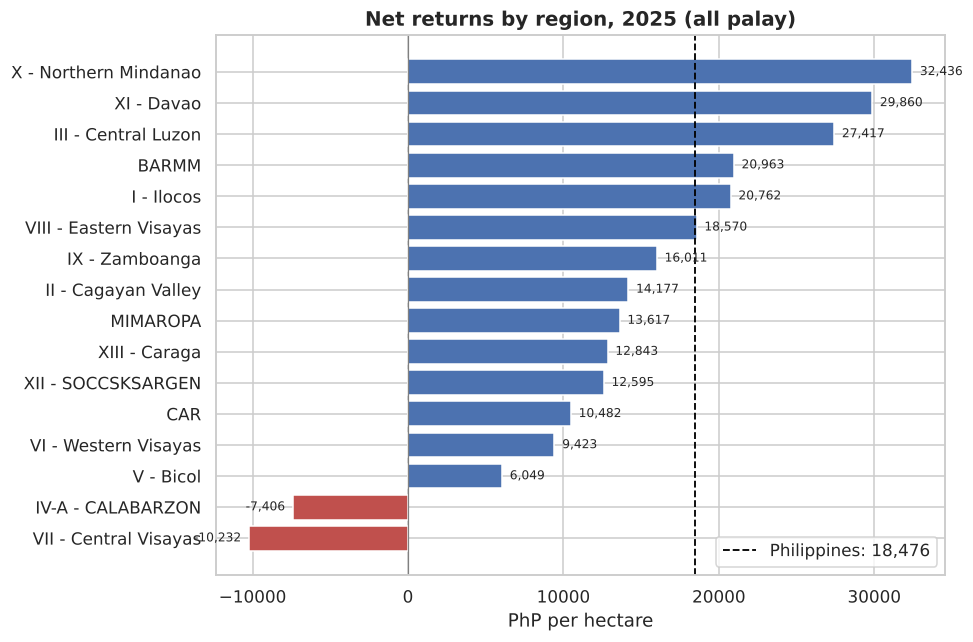

In [ ]:
r25 = get("NET RETURNS", regions=True)
r25 = r25[r25.Year == 2025].sort_values("Value")
nat25 = get("NET RETURNS").query("Year == 2025")["Value"].iloc[0]

fig, ax = plt.subplots(figsize=(9, 6))
colors = ["#c0504d" if v < 0 else "#4c72b0" for v in r25["Value"]]
ax.barh(r25["Region"], r25["Value"], color=colors)
ax.axvline(nat25, color="black", ls="--", lw=1.2, label=f"Philippines: {nat25:,.0f}")
ax.axvline(0, color="grey", lw=0.8)
for y, v in enumerate(r25["Value"]):
    ax.text(v + (500 if v >= 0 else -500), y, f"{v:,.0f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.set_title("Net returns by region, 2025 (all palay)"); ax.set_xlabel("PhP per hectare"); ax.legend()
plt.tight_layout(); plt.show()

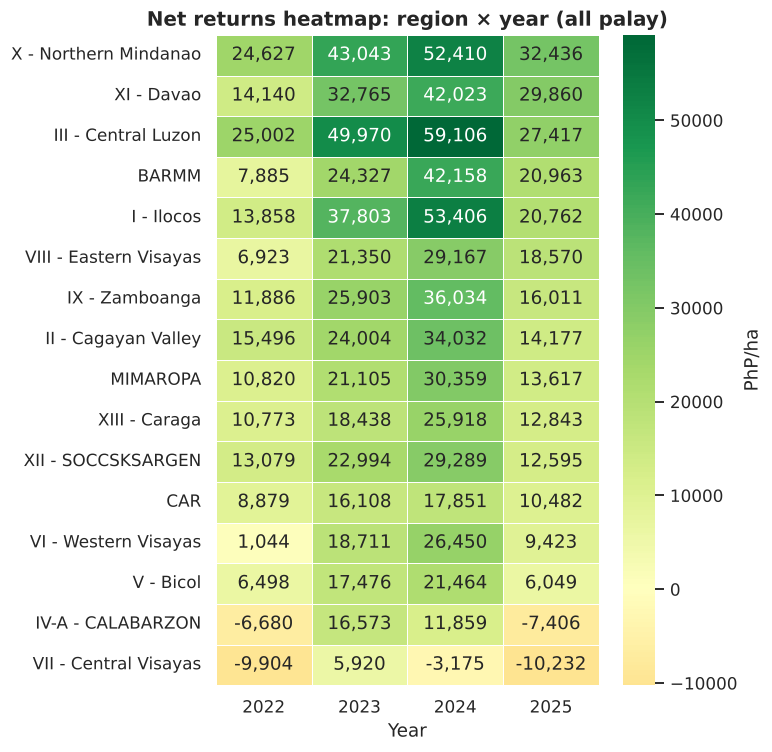

In [ ]:
heat = (get("NET RETURNS", regions=True).pivot(index="Region", columns="Year", values="Value")
        .sort_values(2025, ascending=False))
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(heat, annot=True, fmt=",.0f", cmap="RdYlGn", center=0, linewidths=.5, cbar_kws={"label": "PhP/ha"}, ax=ax)
ax.set_title("Net returns heatmap: region × year (all palay)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

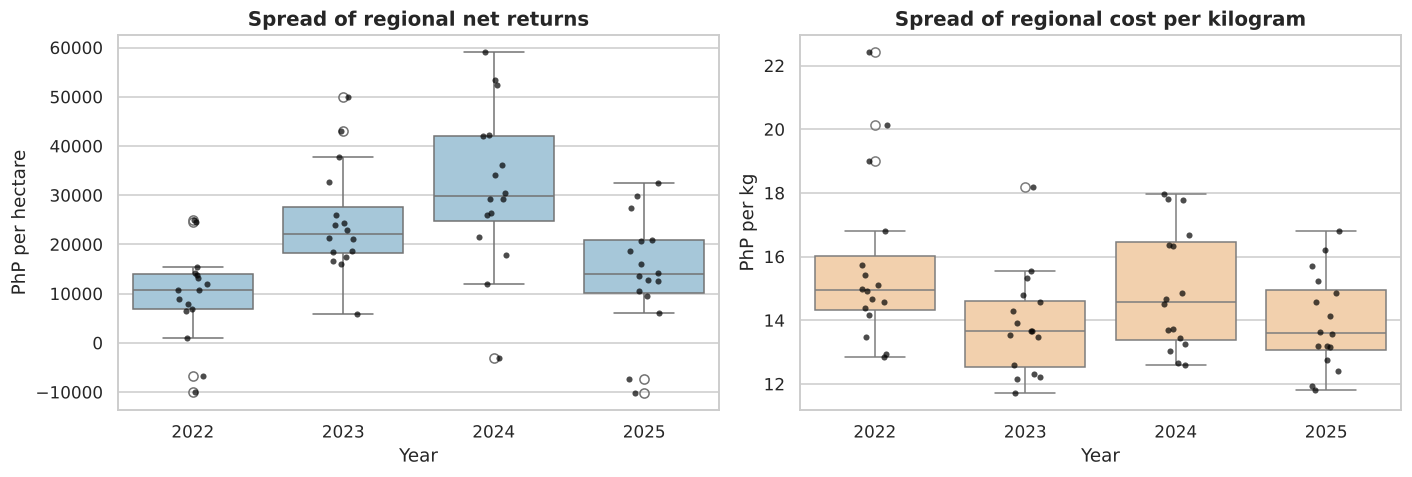

In [ ]:
# How unequal are regions? Spread of net returns and cost per kg across the 16 regions
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=get("NET RETURNS", regions=True), x="Year", y="Value", ax=axes[0], color="#9ecae1")
sns.stripplot(data=get("NET RETURNS", regions=True), x="Year", y="Value", ax=axes[0], color="black", size=4, alpha=.7)
axes[0].set_title("Spread of regional net returns"); axes[0].set_ylabel("PhP per hectare")
sns.boxplot(data=get("Cost per kilogram (in PhP)", regions=True), x="Year", y="Value", ax=axes[1], color="#fdd0a2")
sns.stripplot(data=get("Cost per kilogram (in PhP)", regions=True), x="Year", y="Value", ax=axes[1], color="black", size=4, alpha=.7)
axes[1].set_title("Spread of regional cost per kilogram"); axes[1].set_ylabel("PhP per kg")
plt.tight_layout(); plt.show()

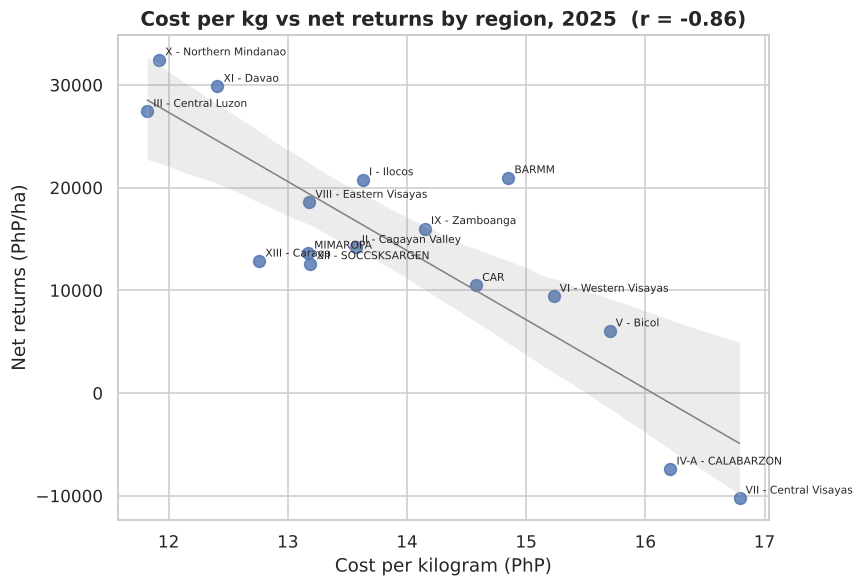

In [ ]:
# Cost efficiency vs profitability (2025): do cheaper-to-produce regions earn more?
a = get("Cost per kilogram (in PhP)", regions=True).query("Year == 2025").set_index("Region")["Value"].rename("Cost per kg")
b = get("NET RETURNS", regions=True).query("Year == 2025").set_index("Region")["Value"].rename("Net returns")
sc = pd.concat([a, b], axis=1)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.regplot(data=sc, x="Cost per kg", y="Net returns", ax=ax, scatter_kws={"s": 60}, line_kws={"color": "grey", "lw": 1})
for r, row in sc.iterrows():
    ax.annotate(r, (row["Cost per kg"], row["Net returns"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
ax.set_title(f"Cost per kg vs net returns by region, 2025  (r = {sc.corr().iloc[0, 1]:.2f})")
ax.set_xlabel("Cost per kilogram (PhP)"); ax.set_ylabel("Net returns (PhP/ha)")
plt.tight_layout(); plt.show()

### 1.5.4 Cropping season: Jan–Jun vs Jul–Dec

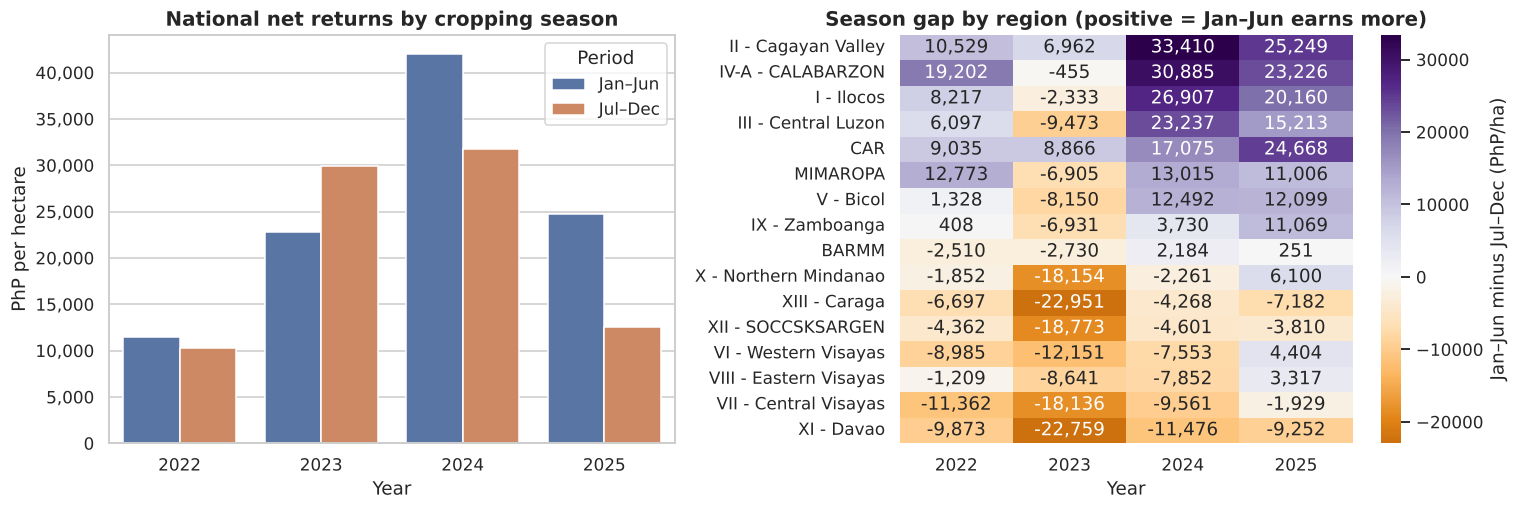

In [ ]:
s = long[(long.Item == "NET RETURNS") & (long.Type == "Palay") & (long.Region == "Philippines") & (long.Period != "Annual average")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.barplot(data=s, x="Year", y="Value", hue="Period", ax=axes[0], palette=["#4c72b0", "#dd8452"])
axes[0].set_title("National net returns by cropping season"); axes[0].set_ylabel("PhP per hectare")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

sr = (get("NET RETURNS", period="Jan–Jun", regions=True).set_index(["Region", "Year"])["Value"]
      - get("NET RETURNS", period="Jul–Dec", regions=True).set_index(["Region", "Year"])["Value"]).unstack()
sns.heatmap(sr.sort_values(2024, ascending=False), annot=True, fmt=",.0f", cmap="PuOr", center=0, ax=axes[1],
            cbar_kws={"label": "Jan–Jun minus Jul–Dec (PhP/ha)"})
axes[1].set_title("Season gap by region (positive = Jan–Jun earns more)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

### 1.5.5 Irrigated vs non-irrigated palay

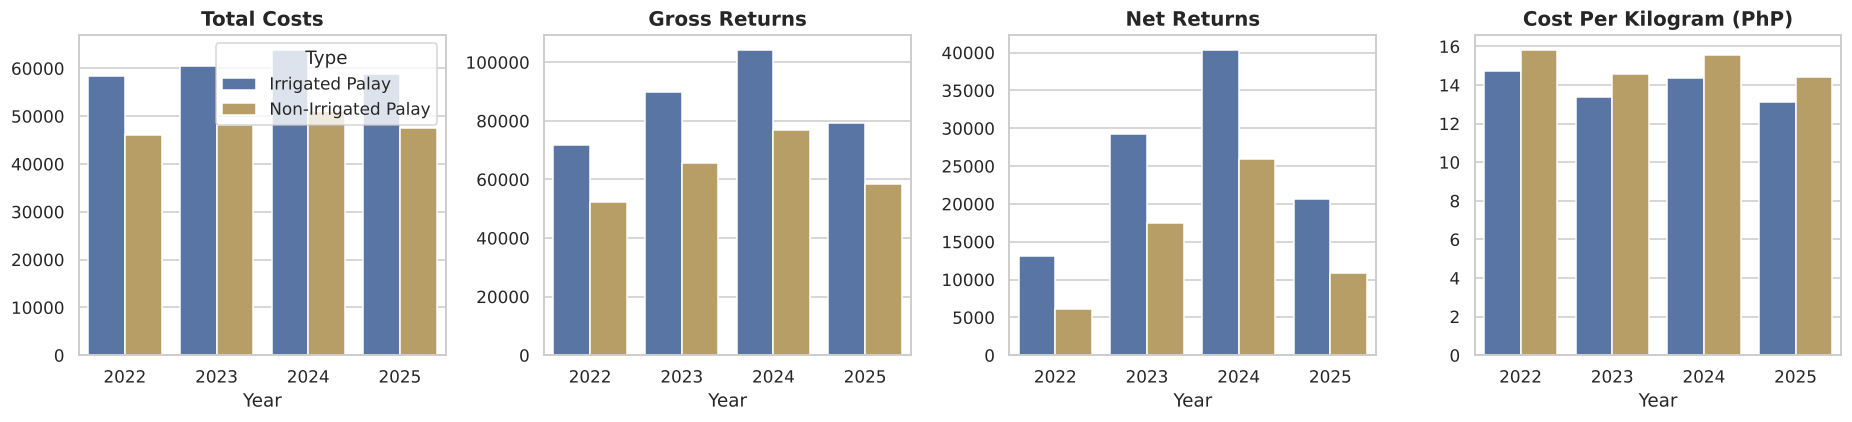

In [ ]:
t = long[(long.Region == "Philippines") & (long.Period == "Annual average") & (long.Item.isin(["TOTAL COSTS", "GROSS RETURNS", "NET RETURNS", "Cost per kilogram (in PhP)"]))
         & (long.Type.isin(["Irrigated Palay", "Non-Irrigated Palay"]))]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, item in zip(axes, ["TOTAL COSTS", "GROSS RETURNS", "NET RETURNS", "Cost per kilogram (in PhP)"]):
    sns.barplot(data=t[t.Item == item], x="Year", y="Value", hue="Type", ax=ax, palette=["#4c72b0", "#c4a35a"])
    ax.set_title(item.title().replace("(In Php)", "(PhP)")); ax.set_ylabel(""); ax.legend_.remove() if ax is not axes[0] else None
plt.tight_layout(); plt.show()

In [ ]:
# Where does the irrigated/non-irrigated net-return gap come from? (national, 2025)
gap = (long[(long.Region == "Philippines") & (long.Period == "Annual average") & (long.Year == 2025)
            & (long.Item.isin(["GROSS RETURNS", "TOTAL COSTS", "NET RETURNS"]))
            & (long.Type.isin(["Irrigated Palay", "Non-Irrigated Palay"]))]
       .pivot(index="Item", columns="Type", values="Value"))
gap["Irrigated − Non-irrigated"] = gap["Irrigated Palay"] - gap["Non-Irrigated Palay"]
gap

Type,Irrigated Palay,Non-Irrigated Palay,Irrigated − Non-irrigated
Item,,,
GROSS RETURNS,"79,347.17","58,391.38","20,955.79"
NET RETURNS,"20,600.51","10,853.14","9,747.37"
TOTAL COSTS,"58,746.66","47,538.24","11,208.42"


### 1.5.6 How do the metrics relate? Correlation across region-years

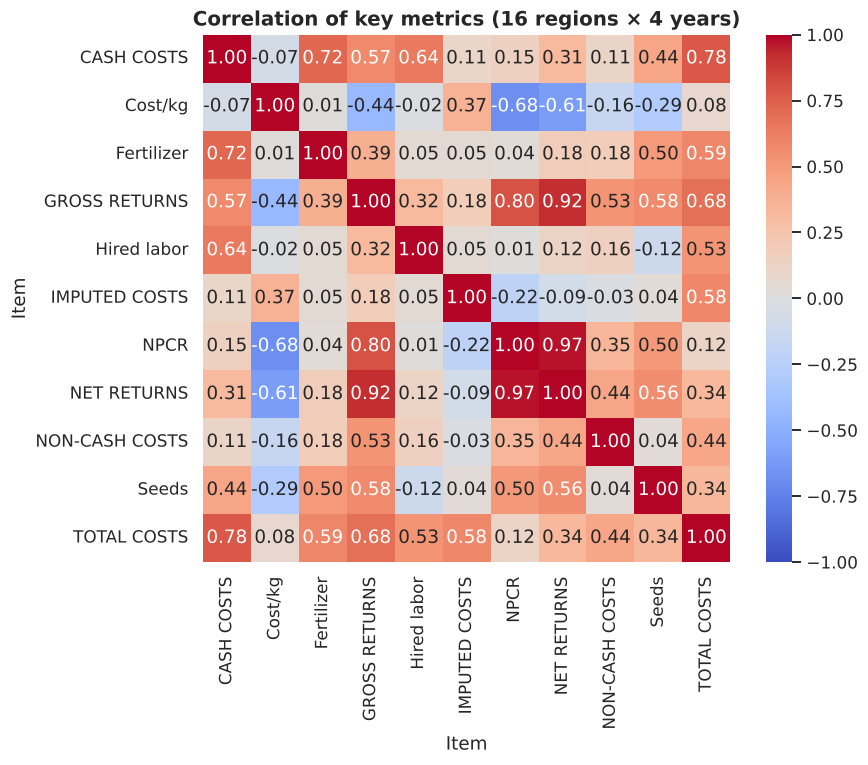

In [ ]:
m = (long[(long.Type == "Palay") & (long.Period == "Annual average") & (long.Region != "Philippines")
          & (long.Item.isin(KEY + ["CASH COSTS", "NON-CASH COSTS", "IMPUTED COSTS", "Fertilizer", "Hired labor", "Seeds"]))]
     .pivot_table(index=["Region", "Year"], columns="Item", values="Value"))
m = m.rename(columns={"Cost per kilogram (in PhP)": "Cost/kg", "NET PROFIT - COST RATIO": "NPCR"})
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(m.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation of key metrics (16 regions × 4 years)")
plt.tight_layout(); plt.show()

---
# Part 2: Research Analysis (irrigated vs non-irrigated palay)
Is Palay getting more expensive?

## 2.1 Setup and data preparation

In [ ]:
!pip -q install statsmodels 2>/dev/null
import re, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from scipy import stats
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 40
PAL = {"Irrigated": "#2E6B4F", "Non-irrigated": "#E39A3B"}

In [ ]:
raw_r = pd.read_csv(CSV_PATH)
raw_r = raw_r.drop(columns=[c for c in raw_r.columns if c.startswith("Unnamed")])
value_cols = list(raw_r.columns[3:])
for c in value_cols:
    raw_r[c] = pd.to_numeric(raw_r[c].replace("..", np.nan), errors="coerce")   # '..' = not available
raw_r["Item"] = raw_r["Item"].str.lstrip(".").str.strip()

# keep the two seasonal columns per year (the 'Average' columns are derived from them)
season_cols = [c for c in value_cols if not c.startswith("Average")]
long_r = raw_r.melt(id_vars=["Type", "Geolocation", "Item"], value_vars=season_cols, var_name="col", value_name="v")
long_r["Season"] = np.where(long_r["col"].str.startswith("January"), "Jan-Jun", "Jul-Dec")
long_r["Year"] = long_r["col"].str[-4:].astype(int)
long_r = long_r[(long_r.Geolocation != "PHILIPPINES") & (long_r.Type != "Palay")]
long_r["Type"] = long_r["Type"].replace({"Irrigated Palay": "Irrigated", "Non-Irrigated Palay": "Non-irrigated"})

w = long_r.pivot_table(index=["Type", "Geolocation", "Year", "Season"], columns="Item", values="v", dropna=False).reset_index()
w = w.rename(columns={"Geolocation": "Region", "TOTAL COSTS": "total_cost", "GROSS RETURNS": "gross", "NET RETURNS": "net",
                      "Cost per kilogram (in PhP)": "cost_kg", "NET PROFIT - COST RATIO": "npcr"})
w["Region"] = w["Region"].str.extract(r"\((.*)\)")[0].fillna(w["Region"]).str.replace(" Region", "", regex=False)
print("Panel shape:", w.shape, "| types:", w.Type.unique().tolist(), "| regions:", w.Region.nunique())

Panel shape: (256, 50) | types: ['Irrigated', 'Non-irrigated'] | regions: 16


### Derived variables
- **Implied yield (kg/ha)** = total cost ÷ cost per kg. The file has no yield column, but cost per kg is total cost divided by output, so output can be recovered.
- **Implied farm-gate price (PhP/kg)** = gross returns ÷ implied yield.
- **Cost groups.** The 36 itemised costs are grouped into 9 groups. Items reported as `..` (not available) count as 0 inside a group.

In [ ]:
groups = {
 "Seeds":           ["Seeds", "Seeds in kind", "Seeds imputed"],
 "Fertilizer":      ["Fertilizer", "Fertilizer in kind", "Fertilizers imputed"],
 "Pesticides":      ["Pesticides", "Pesticides in kind", "Pesticides imputed"],
 "Labor":           ["Hired labor", "Hired labor in kind", "Harvesters' share", "Threshers' share", "Reaper's share",
                     "Caretaker/overseer's wages", "Other permanent employees'salary", "Operator labor", "Family labor", "Exchange labor"],
 "Land":            ["Land tax", "Landowner's share", "Rental value of owned land"],
 "Machinery & fuel":["Rentals", "Rentals in kind", "Fuel & Oil", "Repairs", "Depreciation"],
 "Irrigation fee":  ["Irrigation fee"],
 "Interest":        ["Interest payment on crop loan", "Interest on operating capital"],
 "Other":           ["Transport cost of inputs", "Sacks and tying materials", "Food expense", "Others a/", "Others b/", "Others c/"],
}
G = list(groups)
for g, items in groups.items():
    w[g] = w[items].fillna(0).sum(axis=1)
    w[g + " %"] = w[g] / w["total_cost"] * 100

recon = (w[G].sum(axis=1) - w["total_cost"]).abs()
print(f"Reconciliation: groups sum to total cost within PhP {recon.max():.2f} (max abs gap) -> grouping is complete.")

w["yield_kg"] = w["total_cost"] / w["cost_kg"]
w["price"] = w["gross"] / w["yield_kg"]
w["Irrigated"] = (w.Type == "Irrigated").astype(int)
w["jul_dec"] = (w.Season == "Jul-Dec").astype(int)
w["ln_tc"], w["ln_ckg"], w["ln_yield"] = np.log(w.total_cost), np.log(w.cost_kg), np.log(w.yield_kg)
w[["Type", "Region", "Year", "Season", "total_cost", "cost_kg", "yield_kg", "price", "net"]].head()

Reconciliation: groups sum to total cost within PhP 0.05 (max abs gap) -> grouping is complete.


Item,Type,Region,Year,Season,total_cost,cost_kg,yield_kg,price,net
0,Irrigated,BARMM,2022,Jan-Jun,"47,621.810",24.450,"1,947.722",22.448,"-3,899.960"
1,Irrigated,BARMM,2022,Jul-Dec,"49,547.030",17.550,"2,823.193",22.347,"13,544.200"
2,Irrigated,BARMM,2023,Jan-Jun,"45,099.560",11.860,"3,802.661",18.465,"25,117.840"
3,Irrigated,BARMM,2023,Jul-Dec,"46,630.300",11.830,"3,941.699",20.227,"33,098.710"
4,Irrigated,BARMM,2024,Jan-Jun,"48,986.790",13.120,"3,733.749",25.624,"46,685.360"


## 2.2 Comparative analysis: irrigated vs non-irrigated

In [ ]:
metrics = {"total_cost": "Total cost (PhP/ha)", "cost_kg": "Cost per kg (PhP)", "yield_kg": "Implied yield (kg/ha)",
           "price": "Implied price (PhP/kg)", "gross": "Gross returns (PhP/ha)", "net": "Net returns (PhP/ha)"}
desc = w.groupby("Type")[list(metrics)].agg(["mean", "median", "std"]).T
desc.index = [f"{metrics[a]} | {b}" for a, b in desc.index]
desc

Type,Irrigated,Non-irrigated
Total cost (PhP/ha) | mean,"57,848.640","50,421.660"
Total cost (PhP/ha) | median,"58,378.675","49,703.485"
Total cost (PhP/ha) | std,"8,266.781","10,826.044"
Cost per kg (PhP) | mean,14.273,15.455
Cost per kg (PhP) | median,13.965,14.905
Cost per kg (PhP) | std,2.643,3.047
Implied yield (kg/ha) | mean,"4,146.373","3,304.796"
Implied yield (kg/ha) | median,"4,112.999","3,268.597"
Implied yield (kg/ha) | std,744.069,590.275
Implied price (PhP/kg) | mean,19.542,19.445


In [ ]:
# Paired comparison: same region, year and season, irrigated minus non-irrigated
rows = []
pair = w.pivot_table(index=["Region", "Year", "Season"], columns="Type", values=list(metrics))
for m, label in metrics.items():
    a, b = pair[m]["Irrigated"], pair[m]["Non-irrigated"]
    d = a - b
    t, p = stats.ttest_rel(a, b)
    wp = stats.wilcoxon(a, b).pvalue
    rows.append({"Metric": label, "Irrigated mean": a.mean(), "Non-irrigated mean": b.mean(), "Mean diff": d.mean(),
                 "Diff %": d.mean() / b.mean() * 100, "t (paired)": t, "p (paired t)": p, "p (Wilcoxon)": wp, "Cohen dz": d.mean() / d.std(ddof=1),
                 "% of pairs irrigated higher": (d > 0).mean() * 100})
paired = pd.DataFrame(rows).set_index("Metric")
paired

,Irrigated mean,Non-irrigated mean,Mean diff,Diff %,t (paired),p (paired t),p (Wilcoxon),Cohen dz,% of pairs irrigated higher
Metric,,,,,,,,,
Total cost (PhP/ha),"57,848.640","50,421.660","7,426.980",14.730,10.427,0.000,0.000,0.922,96.094
Cost per kg (PhP),14.273,15.455,-1.182,-7.649,-4.995,0.000,0.000,-0.442,31.250
Implied yield (kg/ha),"4,146.373","3,304.796",841.577,25.465,15.929,0.000,0.000,1.408,96.875
Implied price (PhP/kg),19.542,19.445,0.097,0.500,3.050,0.003,0.020,0.270,58.594
Gross returns (PhP/ha),"81,289.562","64,607.109","16,682.453",25.821,16.460,0.000,0.000,1.455,96.875
Net returns (PhP/ha),"23,440.922","14,185.449","9,255.473",65.246,8.534,0.000,0.000,0.754,81.250


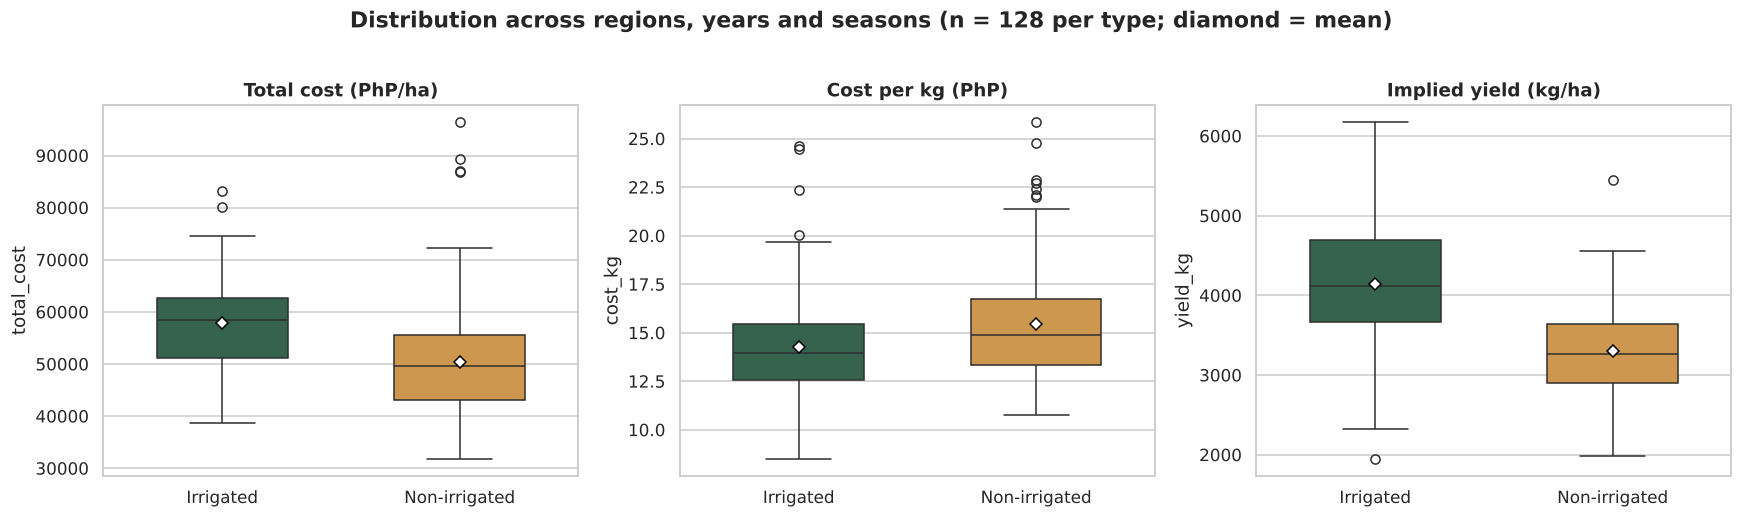

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (m, ttl) in zip(axes, [("total_cost", "Total cost (PhP/ha)"), ("cost_kg", "Cost per kg (PhP)"), ("yield_kg", "Implied yield (kg/ha)")]):
    sns.boxplot(data=w, x="Type", y=m, palette=PAL, ax=ax, width=.55, showmeans=True,
                meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
    ax.set_title(ttl); ax.set_xlabel("")
plt.suptitle("Distribution across regions, years and seasons (n = 128 per type; diamond = mean)", y=1.02, fontweight="bold")
plt.tight_layout(); plt.show()

### Is rice production becoming more expensive? Trend 2022–2025 (nominal PhP)

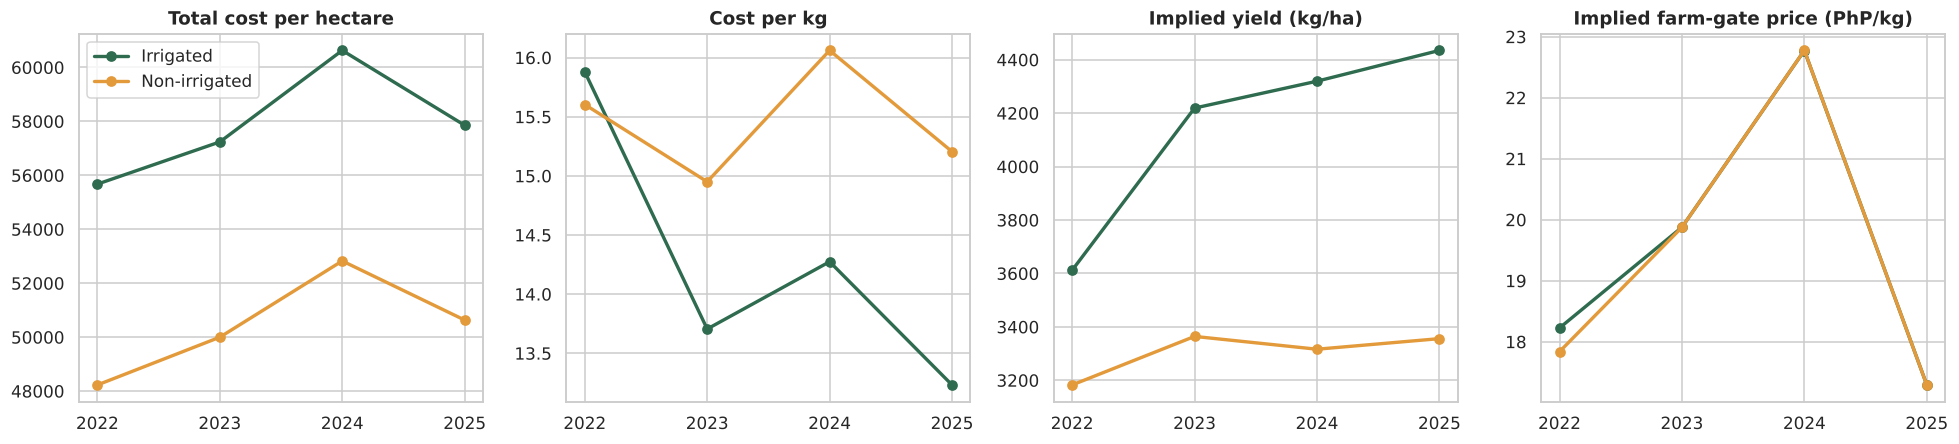

,Total cost 2022→2025 %,Total cost 2022→2024 (peak) %,Cost/kg 2022→2025 %
Type,,,
Irrigated,3.916,8.901,-16.676
Non-irrigated,4.988,9.531,-2.554


In [ ]:
yr = w.groupby(["Type", "Year"])[["total_cost", "cost_kg", "yield_kg", "price", "net"]].mean().reset_index()
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (m, ttl) in zip(axes, [("total_cost", "Total cost per hectare"), ("cost_kg", "Cost per kg"), ("yield_kg", "Implied yield (kg/ha)"), ("price", "Implied farm-gate price (PhP/kg)")]):
    for t, g in yr.groupby("Type"):
        ax.plot(g.Year, g[m], marker="o", lw=2.2, color=PAL[t], label=t)
    ax.set_title(ttl); ax.set_xticks([2022, 2023, 2024, 2025])
axes[0].legend()
plt.tight_layout(); plt.show()

chg = yr.pivot(index="Year", columns="Type", values=["total_cost", "cost_kg"])
summary = pd.DataFrame({
    "Total cost 2022→2025 %": (chg["total_cost"].loc[2025] / chg["total_cost"].loc[2022] - 1) * 100,
    "Total cost 2022→2024 (peak) %": (chg["total_cost"].loc[2024] / chg["total_cost"].loc[2022] - 1) * 100,
    "Cost/kg 2022→2025 %": (chg["cost_kg"].loc[2025] / chg["cost_kg"].loc[2022] - 1) * 100})
summary

## 2.3 Cost contribution analysis
Which expenses make up the cost of producing palay, and does the mix differ between irrigated and non-irrigated farms?

In [ ]:
share = w.groupby("Type")[G].mean()
share_pct = share.div(share.sum(axis=1), axis=0) * 100          # share of mean total cost
tbl = pd.concat({"PhP/ha": share.T, "% of total": share_pct.T}, axis=1)
tbl["Gap (Irr − Non-irr) PhP/ha"] = share.T["Irrigated"] - share.T["Non-irrigated"]
tbl["Share of total-cost gap %"] = tbl["Gap (Irr − Non-irr) PhP/ha"] / tbl["Gap (Irr − Non-irr) PhP/ha"].sum() * 100
tbl.sort_values(("% of total", "Irrigated"), ascending=False)

PhP/ha               % of total                \
Type              Irrigated Non-irrigated  Irrigated Non-irrigated   
Item                                                                 
Labor            25,394.434    22,614.985     43.898        44.852   
Fertilizer        8,135.121     6,506.042     14.063        12.903   
Land              7,653.794     6,276.040     13.231        12.447   
Other             4,403.480     4,167.903      7.612         8.266   
Machinery & fuel  4,134.363     3,726.066      7.147         7.390   
Seeds             3,370.809     3,225.094      5.827         6.396   
Pesticides        2,558.141     2,286.568      4.422         4.535   
Interest          1,998.073     1,618.964      3.454         3.211   
Irrigation fee      200.427         0.000      0.346         0.000   

                 Gap (Irr − Non-irr) PhP/ha Share of total-cost gap %  
Type                                                                   
Item                                                                   
Labor                             2,779.448                    37.424  
Fertilizer                        1,629.079                    21.935  
Land                              1,377.754                    18.551  
Other                               235.578                     3.172  
Machinery & fuel                    408.297                     5.497  
Seeds                               145.715                     1.962  
Pesticides                          271.573                     3.657  
Interest                            379.109                     5.104  
Irrigation fee                      200.427                     2.699

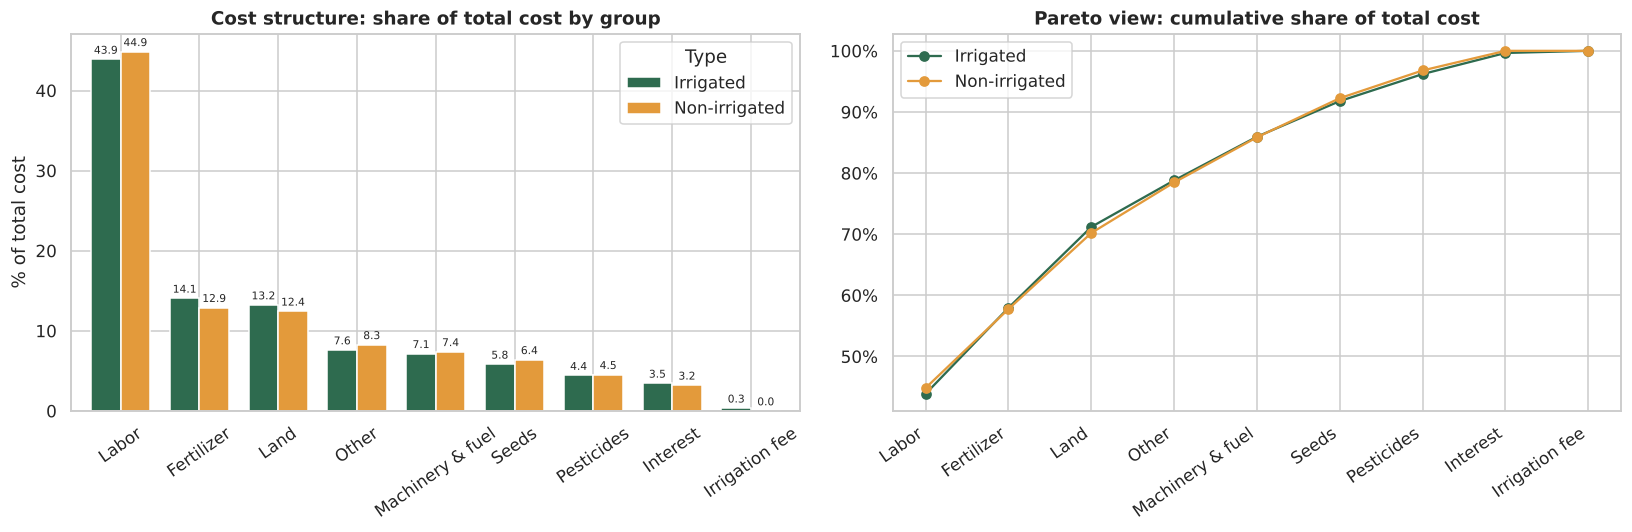

In [ ]:
order = share_pct.mean().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
share_pct[order].T.plot(kind="bar", ax=axes[0], color=[PAL["Irrigated"], PAL["Non-irrigated"]], width=.75)
axes[0].set_ylabel("% of total cost"); axes[0].set_title("Cost structure: share of total cost by group")
axes[0].tick_params(axis="x", rotation=35); axes[0].set_xlabel("")
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.1f", fontsize=7, padding=2)
sc = share_pct[order].T.cumsum()
for t in ["Irrigated", "Non-irrigated"]:
    axes[1].plot(range(len(order)), sc[t], marker="o", color=PAL[t], label=t)
axes[1].set_xticks(range(len(order))); axes[1].set_xticklabels(order, rotation=35, ha="right")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter()); axes[1].set_title("Pareto view: cumulative share of total cost"); axes[1].legend()
plt.tight_layout(); plt.show()

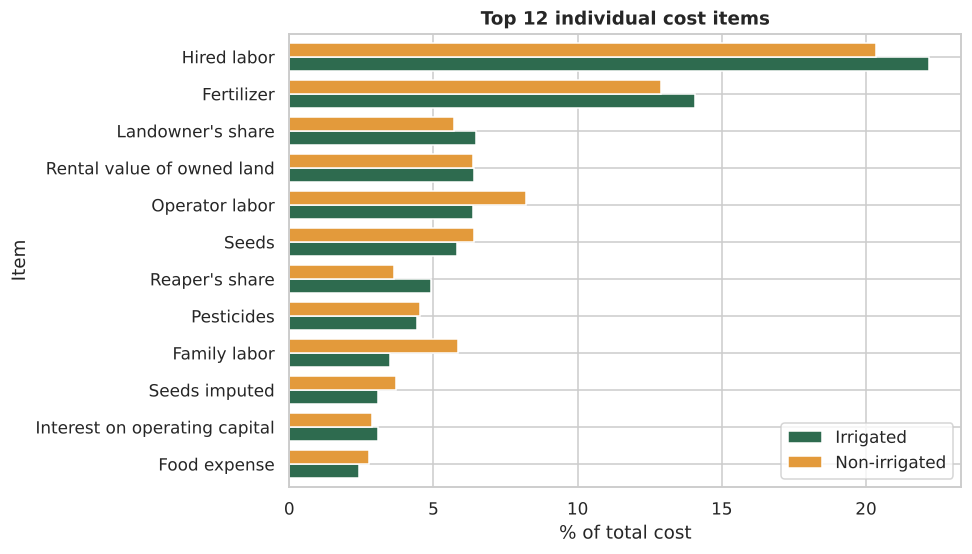

,Irrigated,Non-irrigated,Group
Item,,,
Hired labor,22.198,20.333,Labor
Fertilizer,14.063,12.903,Fertilizer
Landowner's share,6.476,5.704,Land
Rental value of owned land,6.392,6.357,Land
Operator labor,6.368,8.212,Labor
Seeds,5.827,6.396,Seeds
Reaper's share,4.906,3.626,Labor
Pesticides,4.422,4.535,Pesticides
Family labor,3.482,5.859,Labor


In [ ]:
# Largest individual cost items (share of total cost, pooled panel means)
sub_items = [i for items in groups.values() for i in items]
item_share = {t: (w[w.Type == t][sub_items].fillna(0).mean() / w[w.Type == t]["total_cost"].mean() * 100) for t in ["Irrigated", "Non-irrigated"]}
item_tbl = pd.DataFrame(item_share)
item_tbl["Group"] = [next(g for g, it in groups.items() if i in it) for i in item_tbl.index]
top = item_tbl.sort_values("Irrigated", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 5.2))
top[["Irrigated", "Non-irrigated"]][::-1].plot(kind="barh", ax=ax, color=[PAL["Irrigated"], PAL["Non-irrigated"]], width=.75)
ax.set_xlabel("% of total cost"); ax.set_title("Top 12 individual cost items")
plt.tight_layout(); plt.show()
top

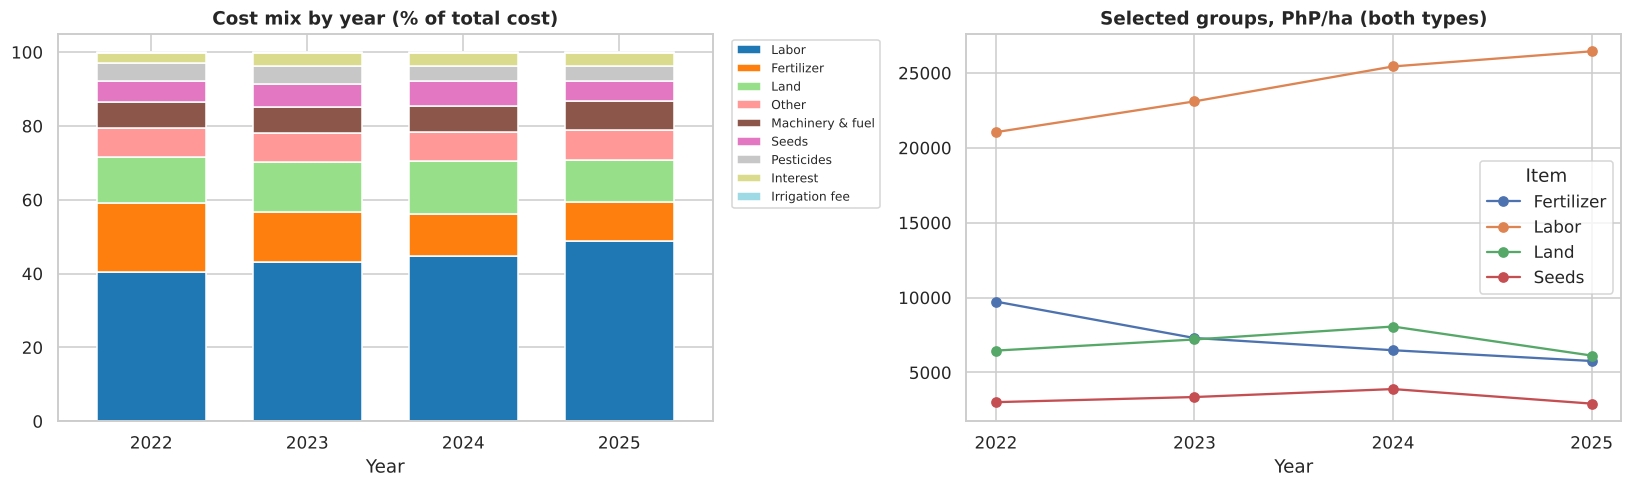

,% change 2022→2025
Item,
Fertilizer,-40.749
Pesticides,-8.084
Land,-5.138
Irrigation fee,-4.637
Seeds,-3.255
Other,10.831
Machinery & fuel,16.637
Labor,25.641
Interest,30.273


In [ ]:
# How the cost mix changed over time (share of total cost, both types pooled)
mix = w.groupby("Year")[G].mean()
mix_pct = mix.div(mix.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
mix_pct[order].plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20", width=.7)
axes[0].set_title("Cost mix by year (% of total cost)"); axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8); axes[0].tick_params(axis="x", rotation=0)
(mix[["Fertilizer", "Labor", "Land", "Seeds"]]).plot(marker="o", ax=axes[1]); axes[1].set_title("Selected groups, PhP/ha (both types)"); axes[1].set_xticks(mix.index)
plt.tight_layout(); plt.show()
(mix.loc[2025] / mix.loc[2022] - 1).mul(100).sort_values().rename("% change 2022→2025").to_frame()

## 2.4 ANOVA
Questions: do **type** (irrigated / non-irrigated), **cropping season**, **year** and **region** explain differences in (a) total cost per hectare and (b) cost per kilogram? Because the same regions appear repeatedly, region is included as a blocking factor.

In [ ]:
def anova_table(formula, data=w):
    model = smf.ols(formula, data).fit()
    a = sm.stats.anova_lm(model, typ=2)
    a["partial η²"] = a["sum_sq"] / (a["sum_sq"] + a.loc["Residual", "sum_sq"])
    a.loc["Residual", ["F", "PR(>F)", "partial η²"]] = np.nan
    return model, a

m_tc, a_tc = anova_table("total_cost ~ C(Type) * C(Year) + C(Season) + C(Region)")
m_ck, a_ck = anova_table("cost_kg ~ C(Type) * C(Year) + C(Season) + C(Region)")
print("Total cost per hectare (PhP):"); display(a_tc)
print("Cost per kilogram (PhP):"); display(a_ck)

Total cost per hectare (PhP):


,sum_sq,df,F,PR(>F),partial η²
C(Type),"3,530,241,968.636",1.000,108.898,0.000,0.319
C(Year),"753,141,733.711",3.000,7.744,0.000,0.091
C(Season),"142,109,421.432",1.000,4.384,0.037,0.019
C(Region),"15,144,223,437.098",15.000,31.144,0.000,0.668
C(Type):C(Year),"3,534,201.136",3.000,0.036,0.991,0.000
Residual,"7,520,938,685.219",232.000,NaN,NaN,NaN


Cost per kilogram (PhP):


,sum_sq,df,F,PR(>F),partial η²
C(Type),89.444,1.000,17.173,0.000,0.069
C(Year),100.283,3.000,6.418,0.000,0.077
C(Season),13.496,1.000,2.591,0.109,0.011
C(Region),694.331,15.000,8.888,0.000,0.365
C(Type):C(Year),49.971,3.000,3.198,0.024,0.040
Residual,"1,208.324",232.000,NaN,NaN,NaN


In [ ]:
# One-way ANOVA / Kruskal-Wallis per factor (simple, one factor at a time), plus assumption checks
rows = []
for dv in ["total_cost", "cost_kg"]:
    for f in ["Type", "Season", "Year", "Region"]:
        groups_ = [g[dv].values for _, g in w.groupby(f)]
        F, p = stats.f_oneway(*groups_); H, pk = stats.kruskal(*groups_)
        lev = stats.levene(*groups_).pvalue
        rows.append({"DV": dv, "Factor": f, "k groups": len(groups_), "F": F, "p (ANOVA)": p, "H (Kruskal)": H, "p (Kruskal)": pk, "Levene p": lev})
oneway = pd.DataFrame(rows); display(oneway)
for name, m in [("total_cost", m_tc), ("cost_kg", m_ck)]:
    print(f"{name}: Shapiro-Wilk on residuals p = {stats.shapiro(m.resid).pvalue:.4f}; R² = {m.rsquared:.3f}")

,DV,Factor,k groups,F,p (ANOVA),H (Kruskal),p (Kruskal),Levene p
0,total_cost,Type,2,38.053,0.000,48.563,0.000,0.104
1,total_cost,Season,2,1.339,0.248,1.578,0.209,0.964
2,total_cost,Year,4,2.402,0.068,8.084,0.044,0.768
3,total_cost,Region,16,20.277,0.000,131.222,0.000,0.003
4,cost_kg,Type,2,10.994,0.001,10.137,0.001,0.154
5,cost_kg,Season,2,1.600,0.207,1.117,0.291,0.829
6,cost_kg,Year,4,4.098,0.007,11.606,0.009,0.389
7,cost_kg,Region,16,7.601,0.000,82.997,0.000,0.000


total_cost: Shapiro-Wilk on residuals p = 0.0000; R² = 0.722
cost_kg: Shapiro-Wilk on residuals p = 0.0002; R² = 0.440


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
  2022   2023  -1.4141  0.028 -2.7198 -0.1083   True
  2022   2024  -0.5742 0.6668   -1.88  0.7315  False
  2022   2025  -1.5233 0.0148  -2.829 -0.2175   True
  2023   2024   0.8398 0.3453 -0.4659  2.1456  False
  2023   2025  -0.1092 0.9964  -1.415  1.1965  False
  2024   2025  -0.9491 0.2394 -2.2548  0.3567  False
----------------------------------------------------


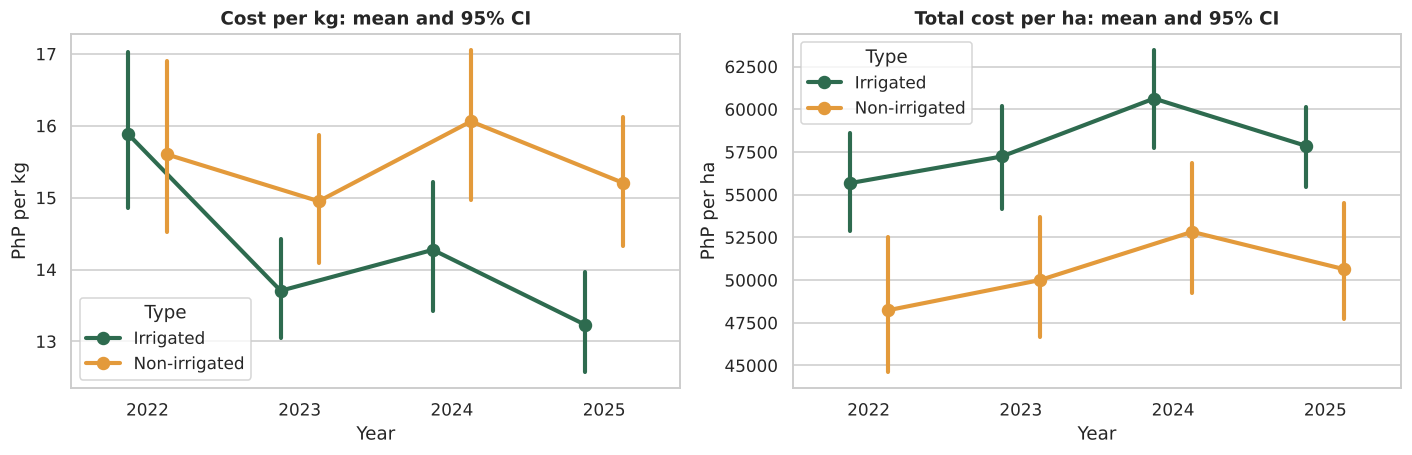

In [ ]:
# Post-hoc: which years differ in cost per kg? (Tukey HSD)
tuk = pairwise_tukeyhsd(w["cost_kg"], w["Year"])
print(tuk.summary())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
sns.pointplot(data=w, x="Year", y="cost_kg", hue="Type", palette=PAL, errorbar=("ci", 95), dodge=.25, ax=axes[0])
axes[0].set_title("Cost per kg: mean and 95% CI"); axes[0].set_ylabel("PhP per kg")
sns.pointplot(data=w, x="Year", y="total_cost", hue="Type", palette=PAL, errorbar=("ci", 95), dodge=.25, ax=axes[1])
axes[1].set_title("Total cost per ha: mean and 95% CI"); axes[1].set_ylabel("PhP per ha")
plt.tight_layout(); plt.show()

In [ ]:
# Do the two farm types differ in COST STRUCTURE? ANOVA on each cost-group share (Bonferroni across 9 groups)
rows = []
for g in G:
    a, b = w[w.Type == "Irrigated"][g + " %"], w[w.Type == "Non-irrigated"][g + " %"]
    F, p = stats.f_oneway(a, b)
    rows.append({"Cost group": g, "Irrigated mean %": a.mean(), "Non-irrigated mean %": b.mean(), "Diff (pp)": a.mean() - b.mean(), "F": F, "p": p, "p (Bonferroni)": min(p * len(G), 1)})
struct = pd.DataFrame(rows).set_index("Cost group").sort_values("p"); struct

,Irrigated mean %,Non-irrigated mean %,Diff (pp),F,p,p (Bonferroni)
Cost group,,,,,,
Irrigation fee,0.350,0.000,0.350,196.612,0.000,0.000
Seeds,5.814,6.483,-0.669,7.357,0.007,0.064
Interest,3.458,3.225,0.234,6.794,0.010,0.087
Fertilizer,14.016,12.671,1.345,5.484,0.020,0.180
Other,7.761,8.397,-0.635,2.298,0.131,1.000
Pesticides,4.501,4.786,-0.285,0.926,0.337,1.000
Labor,43.959,44.732,-0.774,0.897,0.345,1.000
Land,13.103,12.570,0.533,0.833,0.362,1.000
Machinery & fuel,7.037,7.137,-0.100,0.087,0.768,1.000


## 2.5 Regression
**Model A.** `ln(total cost per ha) ~ Irrigated + Season + Year + Region`  — the percentage cost premium of irrigated farming after controlling for region, year and season.
**Model B.** Same for `ln(cost per kg)`.
**Model C.** What is associated with cost per kg? Adds implied yield and the cost shares of fertilizer, labor and land.
**Model D.** One regression per cost group: where does the irrigated premium come from (PhP/ha)?

Standard errors are clustered by region (16 clusters, so treat p-values as approximate). Coefficients on `ln(.)` models are read as ≈ percentage changes.

In [ ]:
cl = {"cov_type": "cluster", "cov_kwds": {"groups": w["Region"].astype("category").cat.codes}}
mA = smf.ols("ln_tc ~ Irrigated + jul_dec + C(Year) + C(Region)", w).fit(**cl)
mB = smf.ols("ln_ckg ~ Irrigated + jul_dec + C(Year) + C(Region)", w).fit(**cl)

def tidy(m, keep):
    t = pd.DataFrame({"coef": m.params, "se": m.bse, "p": m.pvalues, "ci_low": m.conf_int()[0], "ci_high": m.conf_int()[1]})
    t = t[t.index.str.contains("|".join(keep))]
    t["≈ % effect"] = (np.exp(t["coef"]) - 1) * 100
    return t
tA, tB = tidy(mA, ["Irrigated", "jul_dec", r"C\(Year\)"]), tidy(mB, ["Irrigated", "jul_dec", r"C\(Year\)"])
print(f"Model A (ln total cost per ha): R² = {mA.rsquared:.3f}, n = {int(mA.nobs)}"); display(tA)
print(f"Model B (ln cost per kg): R² = {mB.rsquared:.3f}, n = {int(mB.nobs)}"); display(tB)

Model A (ln total cost per ha): R² = 0.732, n = 256


,coef,se,p,ci_low,ci_high,≈ % effect
C(Year)[T.2023],0.034,0.013,0.008,0.009,0.059,3.484
C(Year)[T.2024],0.089,0.012,0.000,0.065,0.113,9.336
C(Year)[T.2025],0.048,0.016,0.004,0.015,0.080,4.886
Irrigated,0.148,0.030,0.000,0.088,0.207,15.907
jul_dec,-0.025,0.030,0.402,-0.085,0.034,-2.504


Model B (ln cost per kg): R² = 0.396, n = 256


,coef,se,p,ci_low,ci_high,≈ % effect
C(Year)[T.2023],-0.088,0.040,0.028,-0.168,-0.009,-8.469
C(Year)[T.2024],-0.037,0.047,0.438,-0.129,0.056,-3.605
C(Year)[T.2025],-0.098,0.035,0.005,-0.168,-0.029,-9.380
Irrigated,-0.078,0.030,0.009,-0.137,-0.019,-7.483
jul_dec,-0.032,0.041,0.434,-0.112,0.048,-3.141


In [ ]:
# Model C: drivers of cost per kg
mC = smf.ols("ln_ckg ~ Irrigated + ln_yield + Q('Labor %') + Q('Fertilizer %') + Q('Land %') + jul_dec + C(Year) + C(Region)", w).fit(**cl)
tC = tidy(mC, ["Irrigated", "ln_yield", "Labor", "Fertilizer", "Land", "jul_dec"])
print(f"Model C: R² = {mC.rsquared:.3f}"); display(tC)

X = w[["Irrigated", "ln_yield", "Labor %", "Fertilizer %", "Land %", "jul_dec"]].assign(const=1.0)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1] - 1)], index=X.columns[:-1], name="VIF")
display(vif.to_frame())

Model C: R² = 0.735


,coef,se,p,ci_low,ci_high,≈ % effect
Irrigated,0.116,0.035,0.001,0.047,0.184,12.249
ln_yield,-0.870,0.084,0.000,-1.034,-0.706,-58.106
Q('Labor %'),0.005,0.004,0.195,-0.002,0.012,0.476
Q('Fertilizer %'),0.002,0.007,0.707,-0.010,0.015,0.245
Q('Land %'),0.006,0.006,0.283,-0.005,0.017,0.594
jul_dec,-0.030,0.028,0.287,-0.086,0.026,-2.984


,VIF
Item,
Irrigated,1.407
ln_yield,1.400
Labor %,1.916
Fertilizer %,1.867
Land %,1.571
jul_dec,1.056


,Irrigated premium (PhP/ha),ci_low,ci_high,p
Outcome,,,,
Seeds,145.715,-30.773,322.203,0.106
Fertilizer,"1,629.079",777.540,"2,480.619",0.000
Pesticides,271.573,-54.150,597.296,0.102
Labor,"2,779.448",752.283,"4,806.614",0.007
Land,"1,377.754",318.539,"2,436.970",0.011
Machinery & fuel,408.297,-503.350,"1,319.945",0.380
Irrigation fee,200.427,116.906,283.948,0.000
Interest,379.109,214.179,544.039,0.000
Other,235.578,-157.733,628.889,0.240


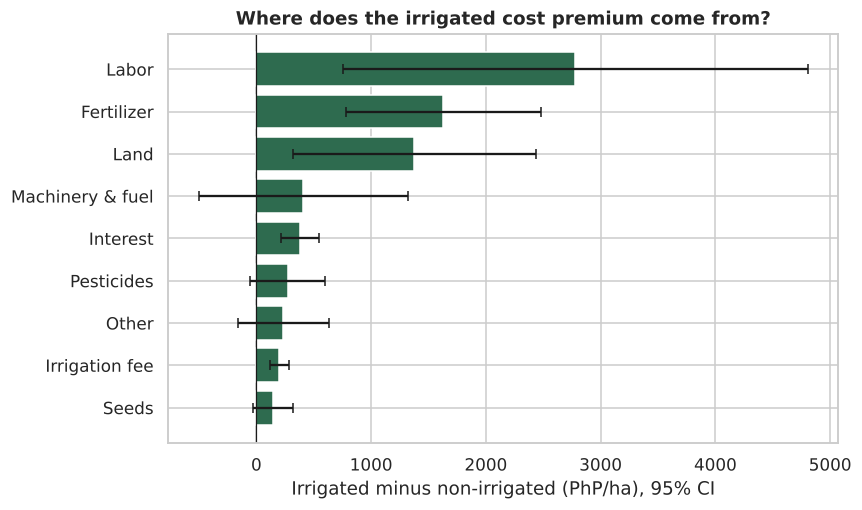

In [ ]:
# Model D: irrigated premium by cost group (PhP/ha, controls: season, year, region)
rows = []
for g in G + ["total_cost"]:
    m = smf.ols(f"Q('{g}') ~ Irrigated + jul_dec + C(Year) + C(Region)", w).fit(**cl)
    ci = m.conf_int().loc["Irrigated"]
    rows.append({"Outcome": g, "Irrigated premium (PhP/ha)": m.params["Irrigated"], "ci_low": ci[0], "ci_high": ci[1], "p": m.pvalues["Irrigated"]})
D = pd.DataFrame(rows).set_index("Outcome"); display(D)
d = D.drop("total_cost").sort_values("Irrigated premium (PhP/ha)")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(d.index, d["Irrigated premium (PhP/ha)"], xerr=[d["Irrigated premium (PhP/ha)"] - d.ci_low, d.ci_high - d["Irrigated premium (PhP/ha)"]],
        color=np.where(d["Irrigated premium (PhP/ha)"] > 0, PAL["Irrigated"], PAL["Non-irrigated"]), capsize=3)
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("Irrigated minus non-irrigated (PhP/ha), 95% CI")
ax.set_title("Where does the irrigated cost premium come from?")
plt.tight_layout(); plt.show()

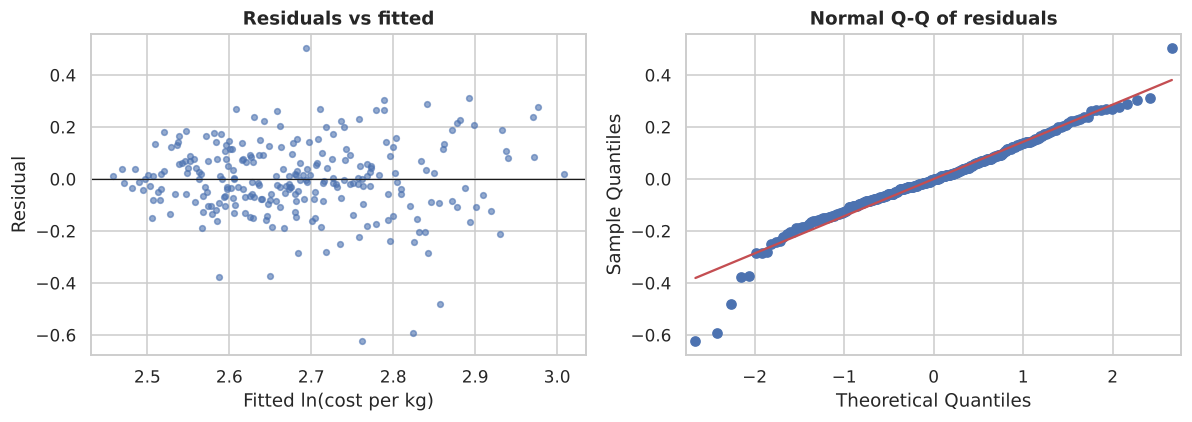

In [ ]:
# Diagnostics for Model B
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(mB.fittedvalues, mB.resid, s=14, alpha=.6); axes[0].axhline(0, color="k", lw=.8)
axes[0].set_xlabel("Fitted ln(cost per kg)"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs fitted")
sm.qqplot(mB.resid, line="s", ax=axes[1]); axes[1].set_title("Normal Q-Q of residuals")
plt.tight_layout(); plt.show()